# Household Appliance Energy Consumption Prediction - Advanced Regression

The goal of this project is to predict household appliance energy consumption using indoor temperature, humidity, outdoor weather conditions, and temporal features.

The dataset contains measurements collected every 10 minutes over approximately 4.5 months in a residential building.

We will explore the dataset, investigate feature distributions and correlations, prepare the data for machine learning, and compare linear, polynomial, and regularized regression models.

## 1. Data Preparation

We will begin by loading the dataset, inspecting its structure, and extracting useful temporal features from the measurement timestamps.

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display
from pandas.plotting import scatter_matrix

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer

energy = pd.read_csv("energydata_complete.csv")


In [22]:
energy['date'] = pd.to_datetime(energy['date'])
energy = energy.sort_values('date').reset_index(drop=True)

energy['hour'] = energy['date'].dt.hour
energy['day_of_week'] = energy['date'].dt.dayofweek
energy['month'] = energy['date'].dt.month
energy['is_weekend'] = (energy['day_of_week'] >= 5).astype(int)

room_names = {
    1: "Kitchen",
    2: "Living_Room",
    3: "Laundry_Room",
    4: "Office",
    5: "Bathroom",
    6: "Outside_North",
    7: "Ironing_Room",
    8: "Teenager_Room_2",
    9: "Parents_Room"
}

rename_dictonary = {}

for i, room in room_names.items():
    rename_dictonary[f"T{i}"] = f"Temperature_{room}"
    rename_dictonary[f"RH_{i}"] = f"Humidity_{room}"

rename_dictonary.update({
    "T_out": "Temperature_Weather_Station",
    "RH_out": "Humidity_Weather_Station",
    "Press_mm_hg": "Pressure_Weather_Station",
    "Windspeed": "Wind_Speed",
    "Visibility": "Visibility",
    "Tdewpoint": "Dew_Point"
})

energy = energy.rename(columns=rename_dictonary)

energy.head()

,date,Appliances,lights,Temperature_Kitchen,Humidity_Kitchen,Temperature_Living_Room,Humidity_Living_Room,Temperature_Laundry_Room,Humidity_Laundry_Room,Temperature_Office,...,Humidity_Weather_Station,Wind_Speed,Visibility,Dew_Point,rv1,rv2,hour,day_of_week,month,is_weekend
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,92.0,7.000000,63.000000,5.3,13.275433,13.275433,17,0,1,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,92.0,6.666667,59.166667,5.2,18.606195,18.606195,17,0,1,0
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,92.0,6.333333,55.333333,5.1,28.642668,28.642668,17,0,1,0
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,92.0,6.000000,51.500000,5.0,45.410389,45.410389,17,0,1,0
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,92.0,5.666667,47.666667,4.9,10.084097,10.084097,17,0,1,0


In [23]:
energy.info()
display(energy.describe())
display(energy.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   date                         19735 non-null  datetime64[us]
 1   Appliances                   19735 non-null  int64         
 2   lights                       19735 non-null  int64         
 3   Temperature_Kitchen          19735 non-null  float64       
 4   Humidity_Kitchen             19735 non-null  float64       
 5   Temperature_Living_Room      19735 non-null  float64       
 6   Humidity_Living_Room         19735 non-null  float64       
 7   Temperature_Laundry_Room     19735 non-null  float64       
 8   Humidity_Laundry_Room        19735 non-null  float64       
 9   Temperature_Office           19735 non-null  float64       
 10  Humidity_Office              19735 non-null  float64       
 11  Temperature_Bathroom         19735 non-null  float64

,date,Appliances,lights,Temperature_Kitchen,Humidity_Kitchen,Temperature_Living_Room,Humidity_Living_Room,Temperature_Laundry_Room,Humidity_Laundry_Room,Temperature_Office,...,Humidity_Weather_Station,Wind_Speed,Visibility,Dew_Point,rv1,rv2,hour,day_of_week,month,is_weekend
count,19735,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,2016-03-20 05:29:59.999999,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,...,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033,11.502002,2.977249,3.101647,0.277274
min,2016-01-11 17:00:00,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,...,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322,0.000000,0.000000,1.000000,0.000000
25%,2016-02-14 23:15:00,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,...,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889,6.000000,1.000000,2.000000,0.000000
50%,2016-03-20 05:30:00,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,...,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653,12.000000,3.000000,3.000000,0.000000
75%,2016-04-23 11:45:00,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,...,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769,17.000000,5.000000,4.000000,1.000000
max,2016-05-27 18:00:00,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,...,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530,23.000000,6.000000,5.000000,1.000000
std,NaN,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,...,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634,6.921953,1.985617,1.339200,0.447664


date                           0
Appliances                     0
lights                         0
Temperature_Kitchen            0
Humidity_Kitchen               0
Temperature_Living_Room        0
Humidity_Living_Room           0
Temperature_Laundry_Room       0
Humidity_Laundry_Room          0
Temperature_Office             0
Humidity_Office                0
Temperature_Bathroom           0
Humidity_Bathroom              0
Temperature_Outside_North      0
Humidity_Outside_North         0
Temperature_Ironing_Room       0
Humidity_Ironing_Room          0
Temperature_Teenager_Room_2    0
Humidity_Teenager_Room_2       0
Temperature_Parents_Room       0
Humidity_Parents_Room          0
Temperature_Weather_Station    0
Pressure_Weather_Station       0
Humidity_Weather_Station       0
Wind_Speed                     0
Visibility                     0
Dew_Point                      0
rv1                            0
rv2                            0
hour                           0
day_of_wee

In [24]:
# energy.hist(bins=50, figsize=(20, 15))
# plt.show()

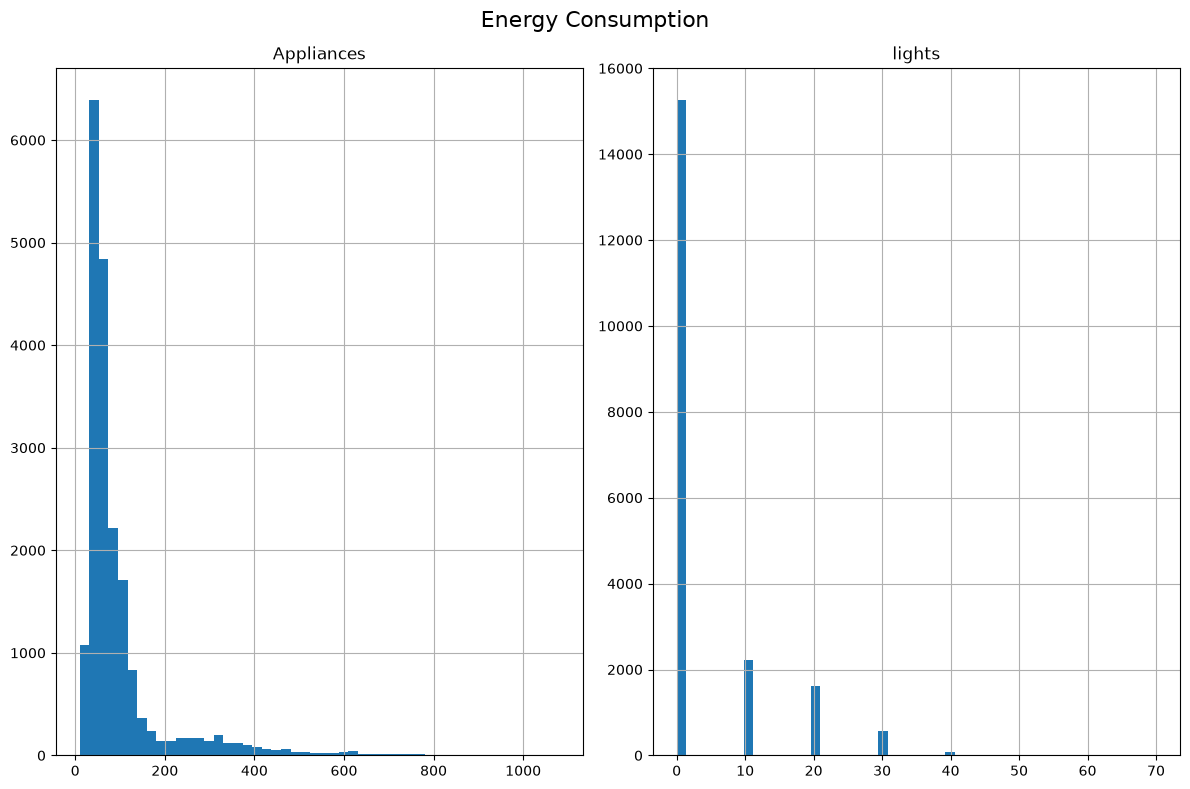

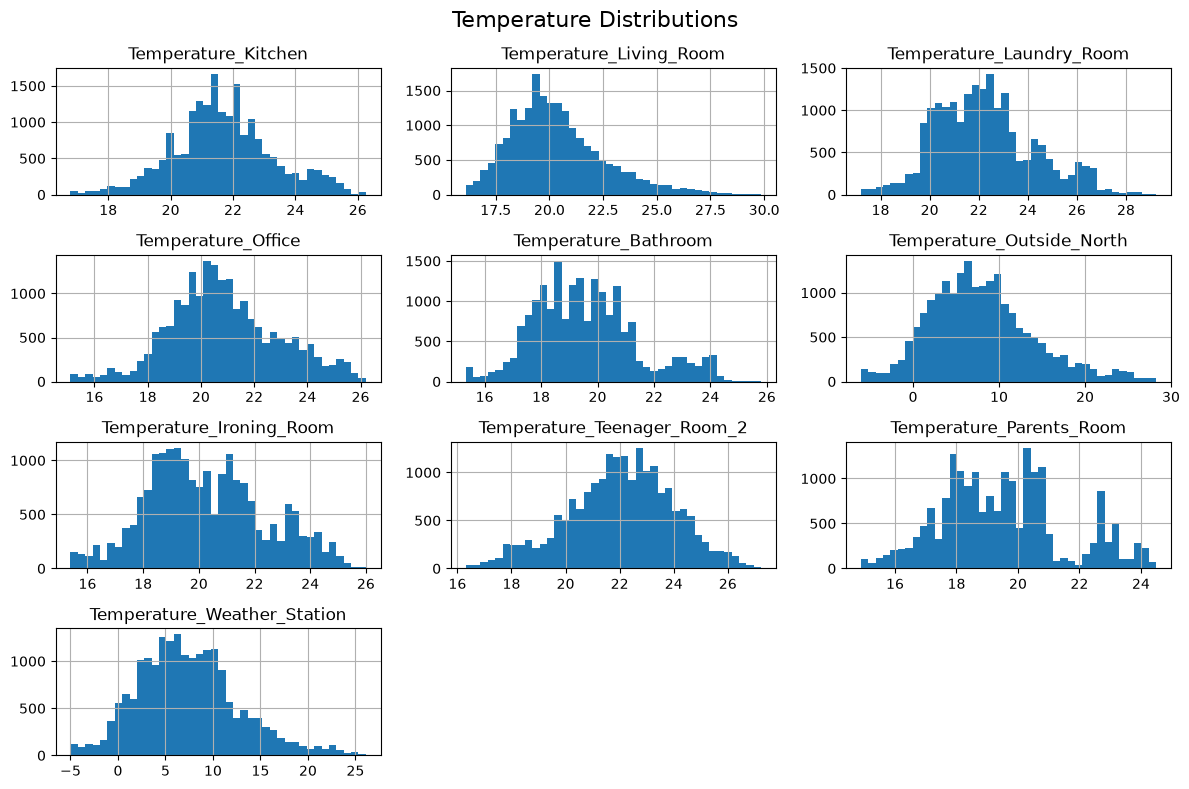

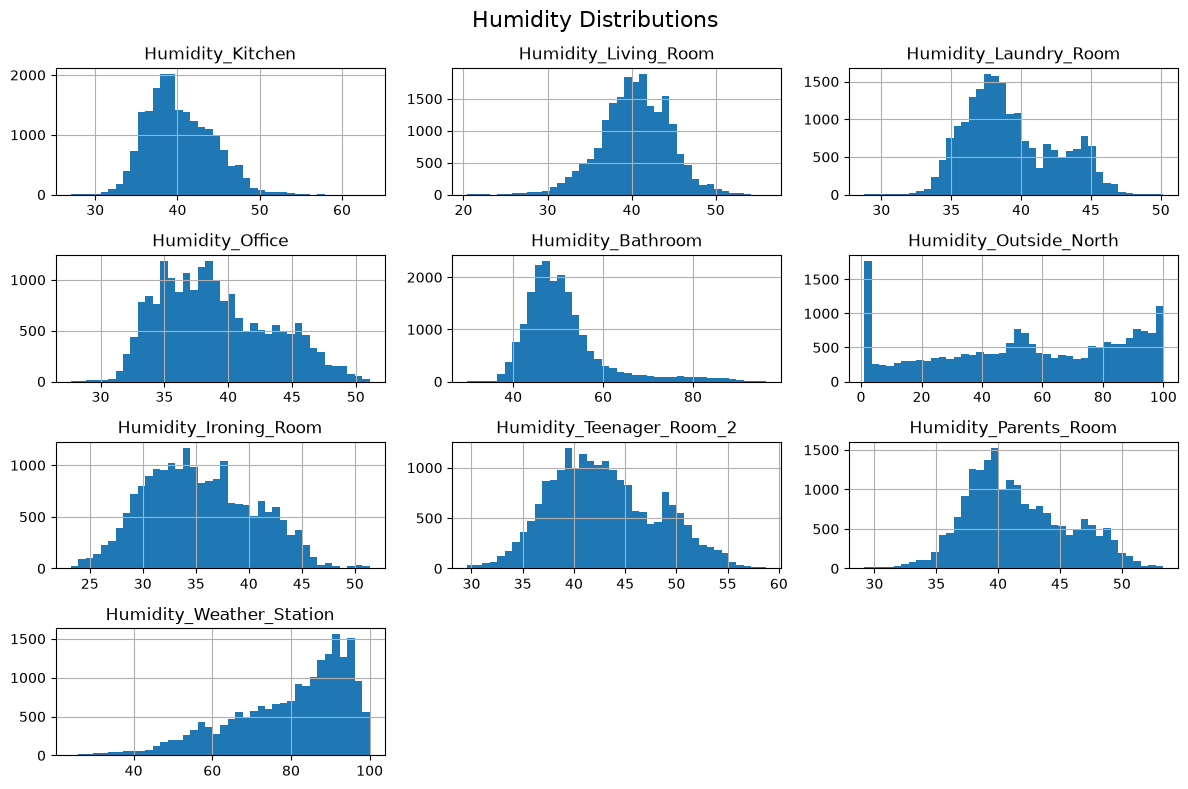

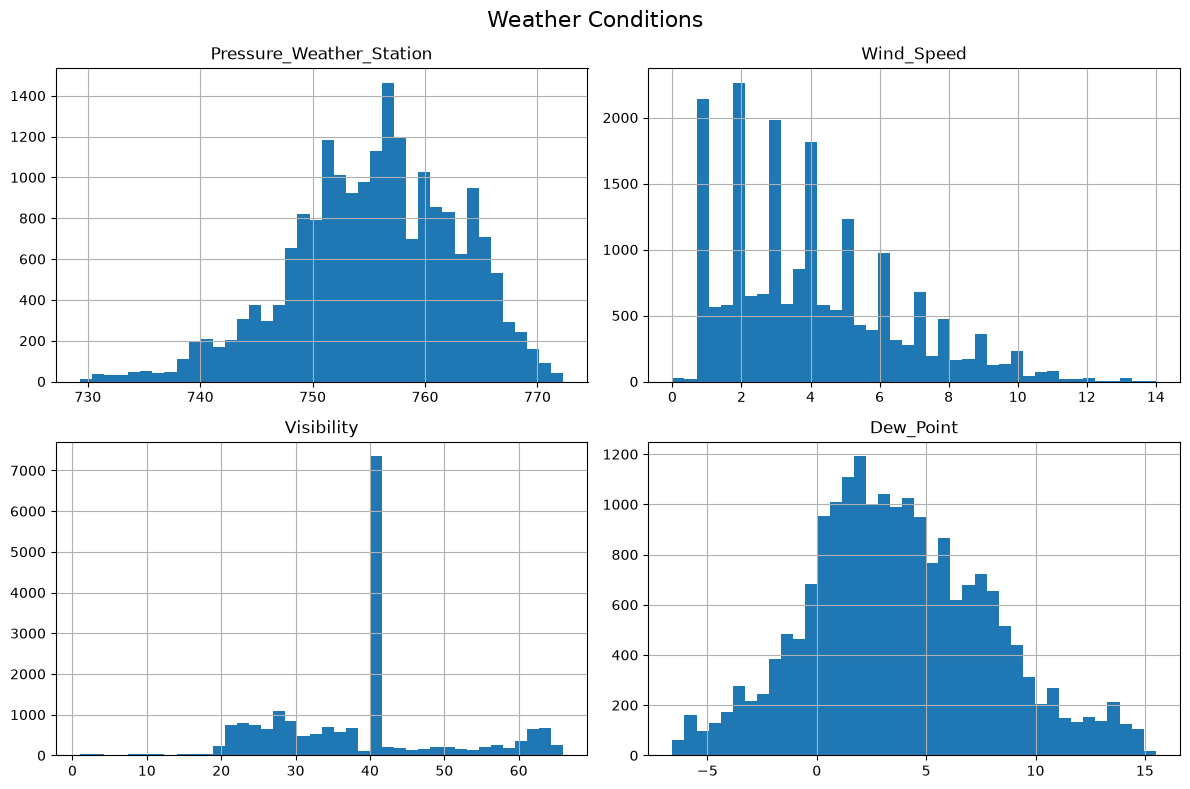

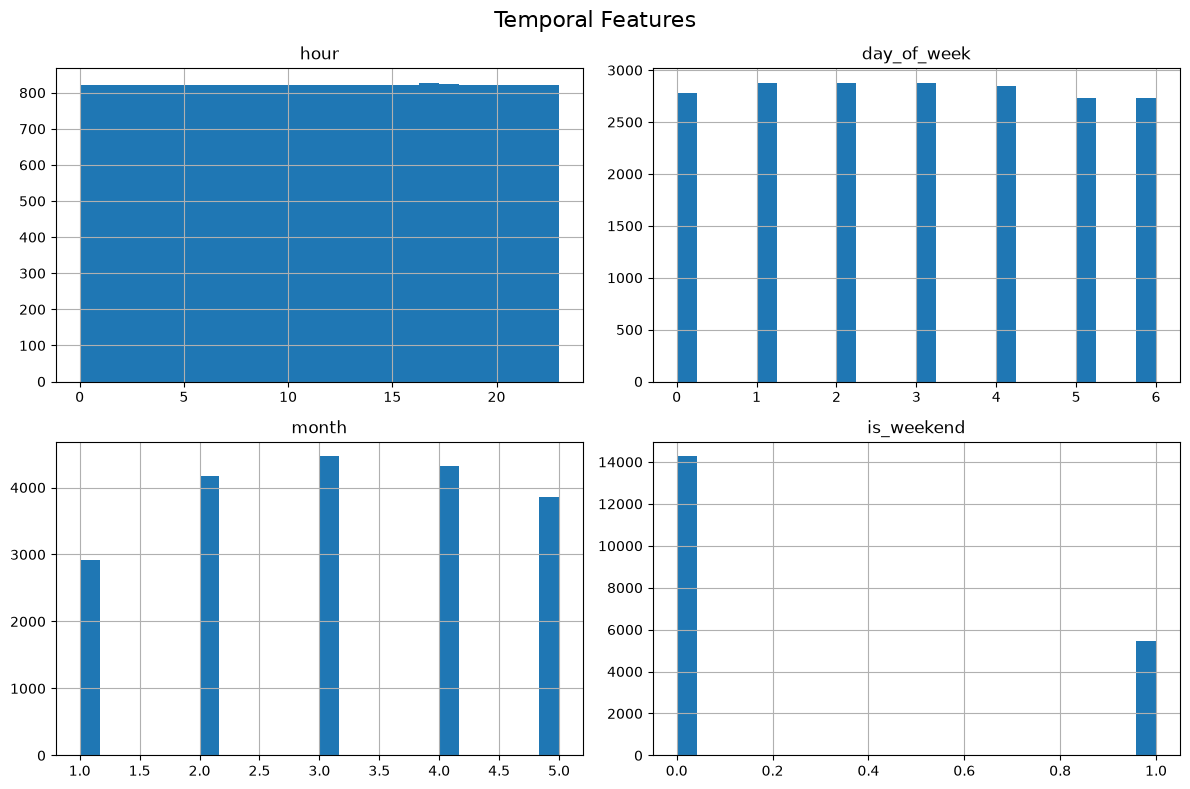

In [25]:
def plot_histograms(data, columns, title, bins=40):
    data[columns].hist(
        bins=bins,
        figsize=(12, 8)
    )
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()


energy_cols = ["Appliances", "lights"]

temperature_cols = [
    col for col in energy.columns
    if col.startswith("Temperature_")
]

humidity_cols = [
    col for col in energy.columns
    if col.startswith("Humidity_")
]

weather_cols = [
    "Pressure_Weather_Station",
    "Wind_Speed",
    "Visibility",
    "Dew_Point"
]

time_cols = ["hour", "day_of_week", "month", "is_weekend"]

plot_histograms(energy, energy_cols, "Energy Consumption", bins=50)

plot_histograms(energy, temperature_cols, "Temperature Distributions")

plot_histograms(energy, humidity_cols, "Humidity Distributions")

plot_histograms(energy, weather_cols, "Weather Conditions")

plot_histograms(energy, time_cols, "Temporal Features", bins=24)


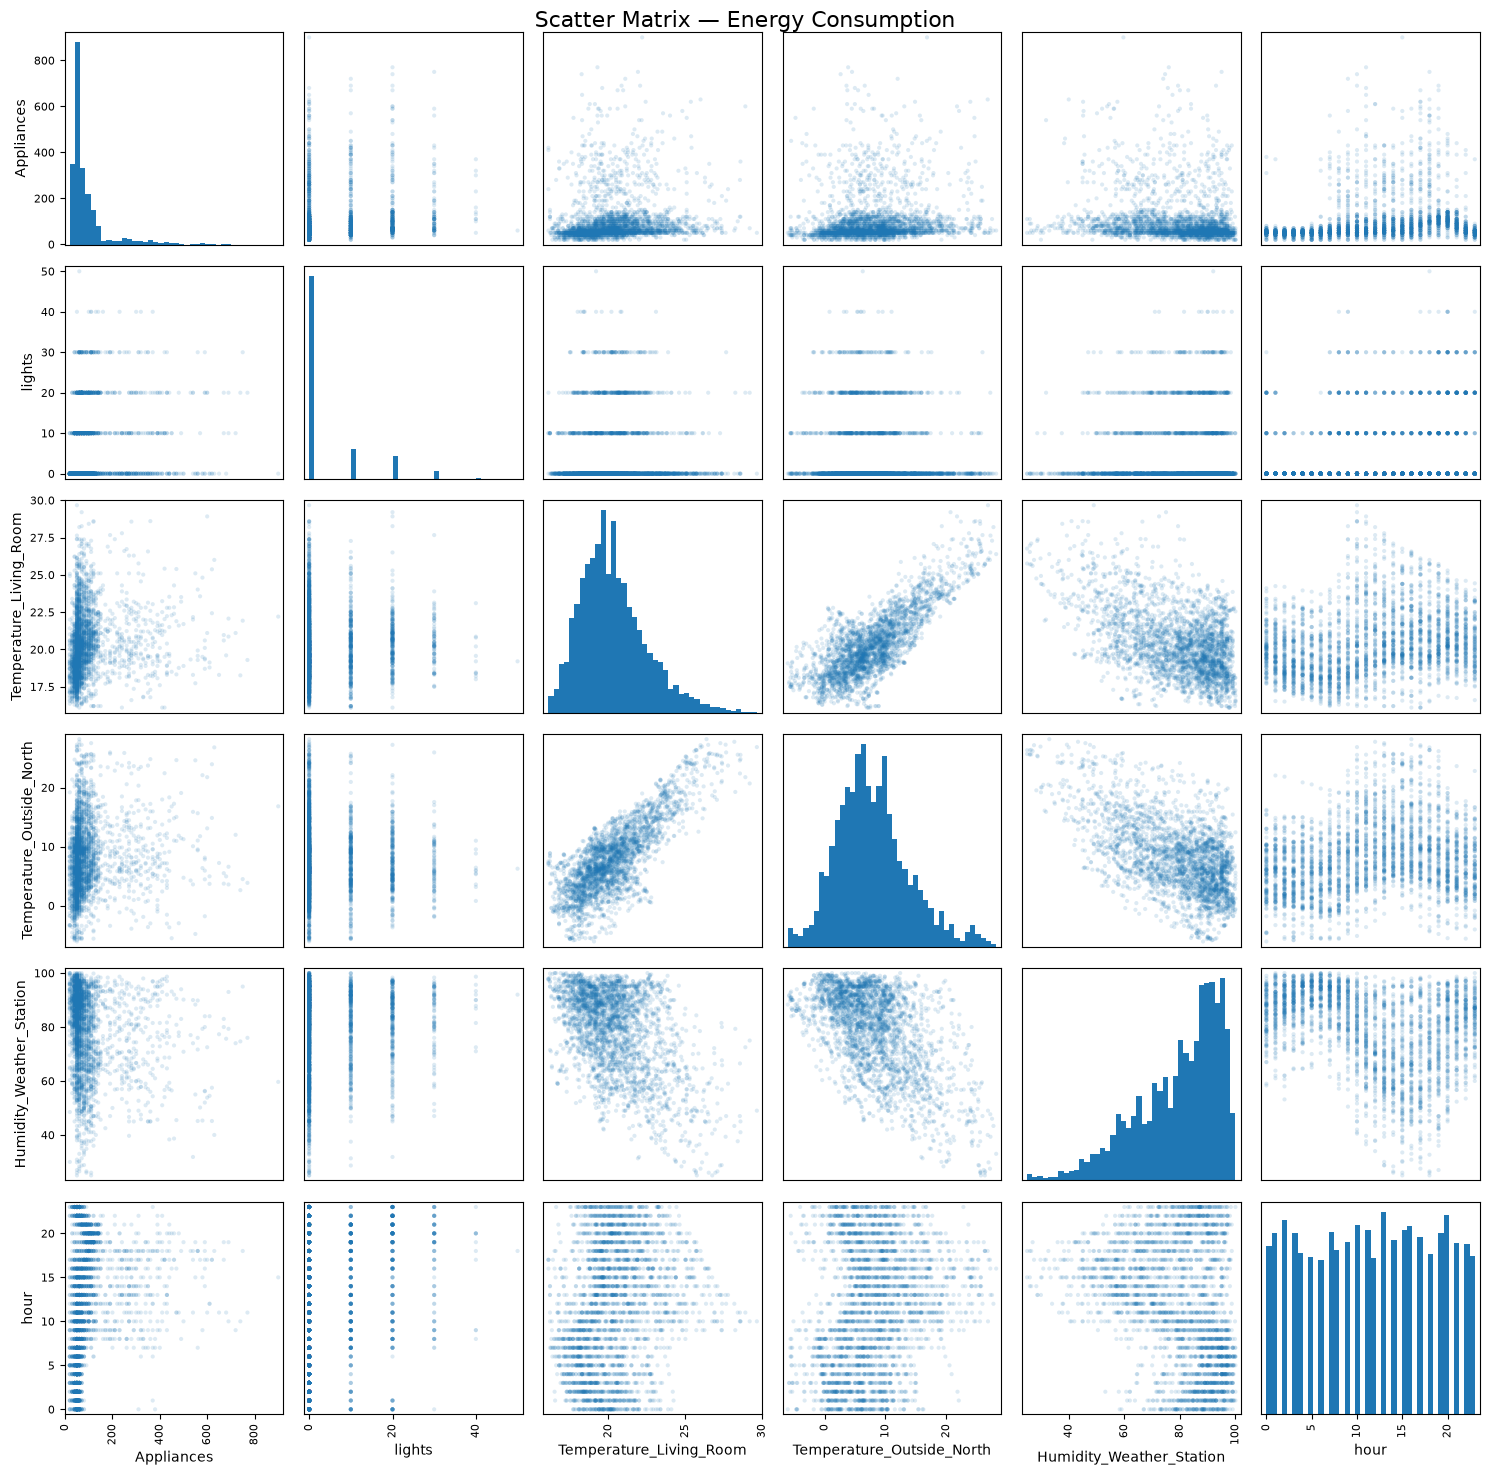

In [27]:
from pandas.plotting import scatter_matrix

scatter_cols = [
    "Appliances",
    "lights",
    "Temperature_Living_Room",
    "Temperature_Outside_North",
    "Humidity_Weather_Station",
    "hour"
]

scatter_matrix(
    energy[scatter_cols].sample(
        n=min(3000, len(energy)),
        random_state=42
    ),
    figsize=(15, 15),
    diagonal="hist",
    alpha=0.15,
    marker=".",
    hist_kwds={"bins": 40, "edgecolor": "none"}
)

plt.suptitle("Scatter Matrix — Energy Consumption", fontsize=16)
plt.tight_layout()
plt.show()


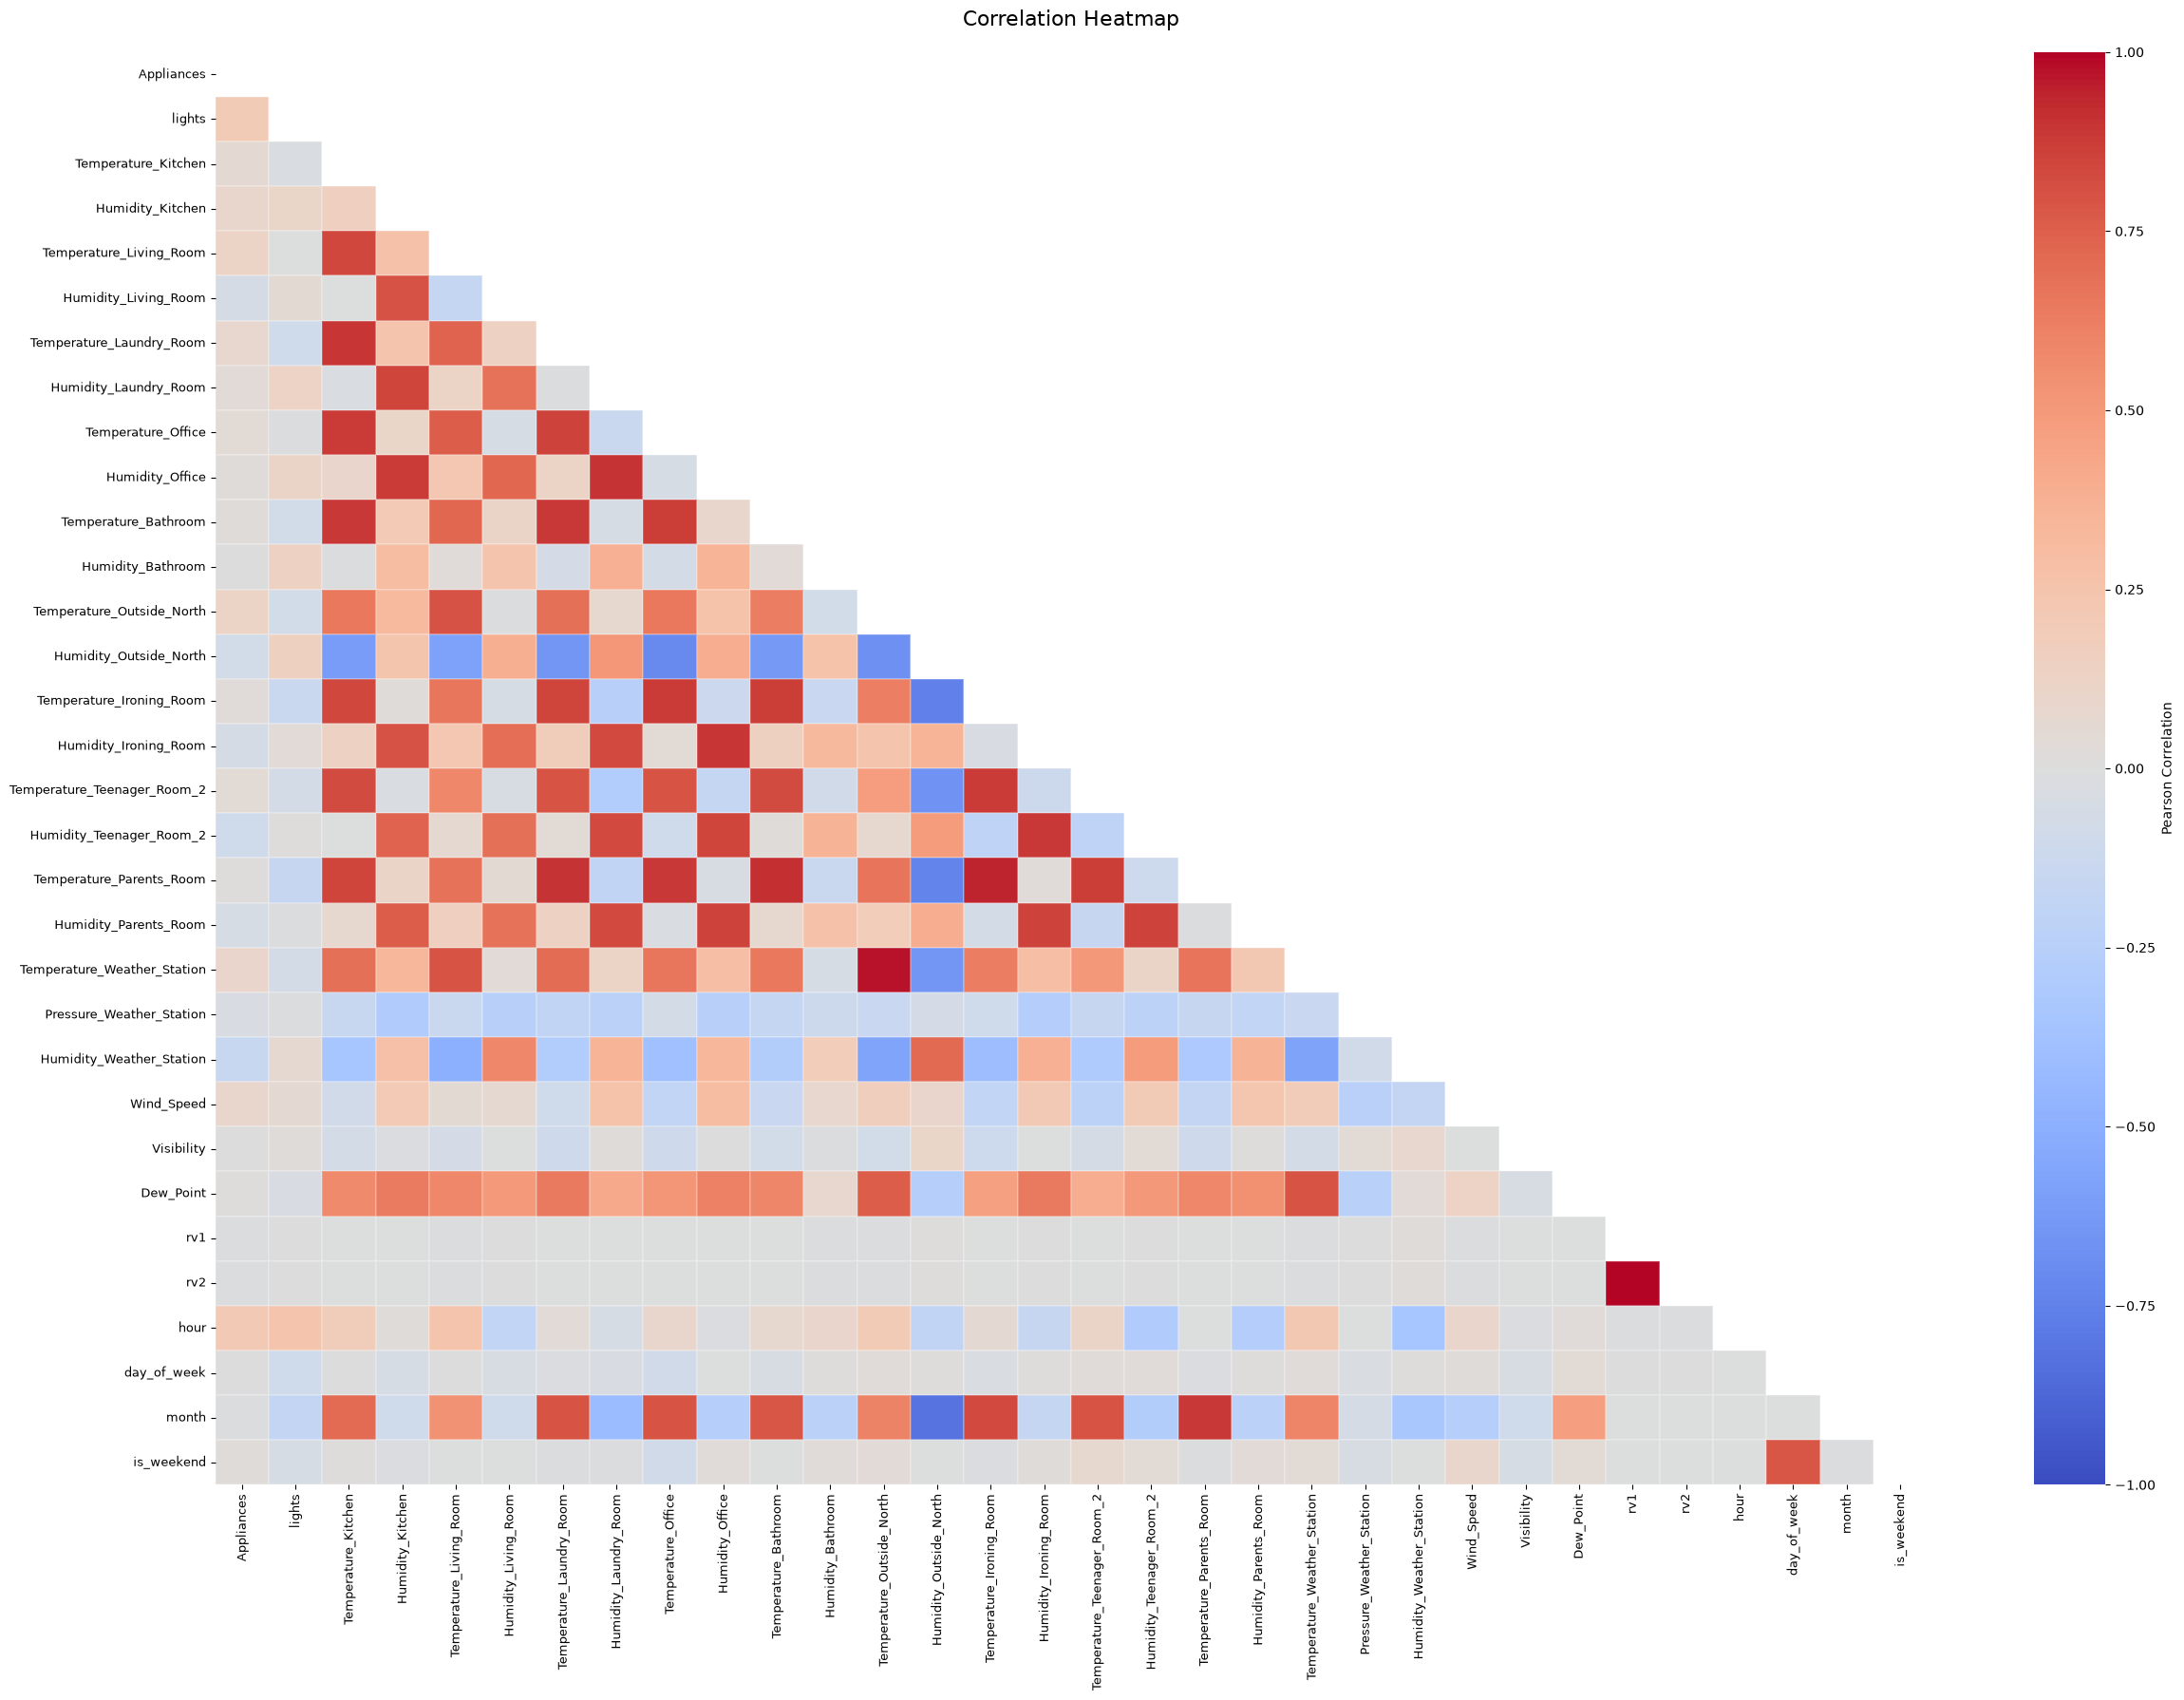

In [30]:
corr_matrix = energy.select_dtypes(include=np.number).corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(25, 18))

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    linewidths=0.3,
    linecolor=(1, 1, 1, 0.2),
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Correlation Heatmap", fontsize=16, pad=20)
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()


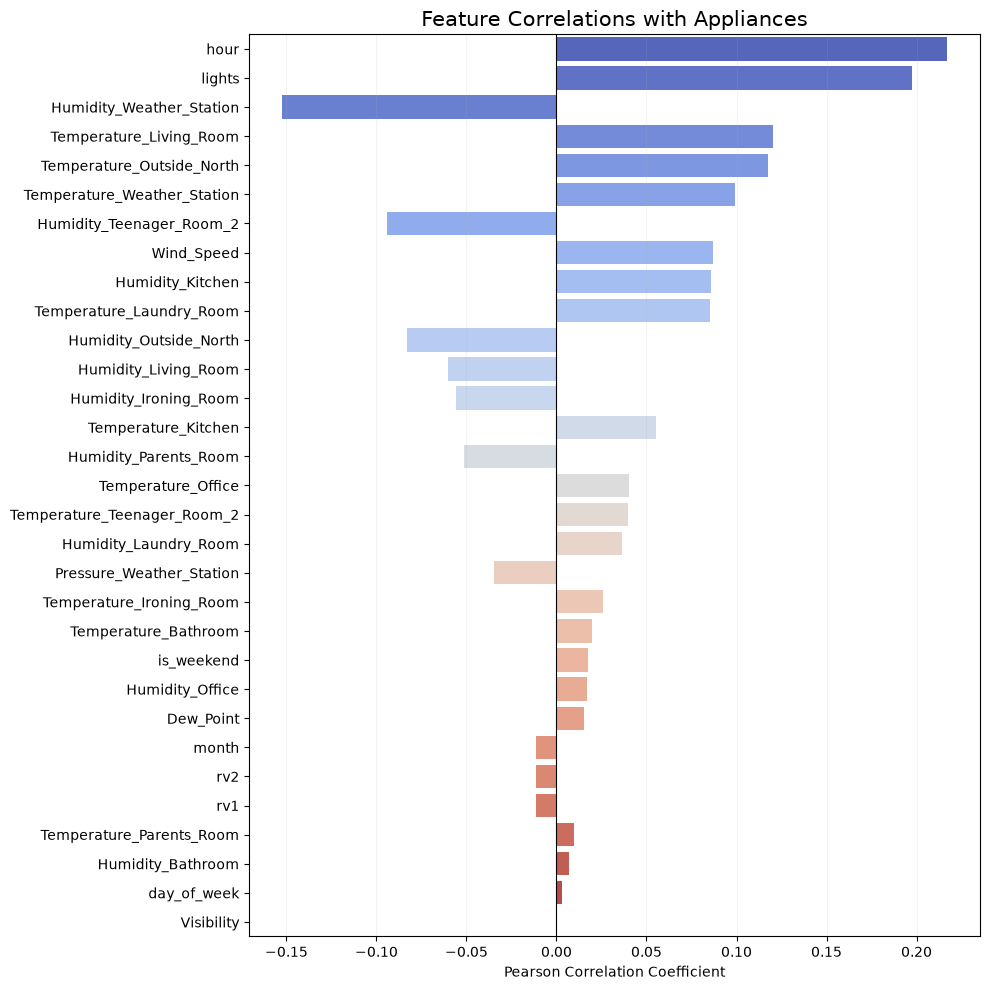

hour                           0.216792
lights                         0.197278
Humidity_Weather_Station      -0.152282
Temperature_Living_Room        0.120073
Temperature_Outside_North      0.117638
Temperature_Weather_Station    0.099155
Humidity_Teenager_Room_2      -0.094039
Wind_Speed                     0.087122
Humidity_Kitchen               0.086031
Temperature_Laundry_Room       0.085060
Humidity_Outside_North        -0.083178
Humidity_Living_Room          -0.060465
Humidity_Ironing_Room         -0.055642
Temperature_Kitchen            0.055447
Humidity_Parents_Room         -0.051462
Temperature_Office             0.040281
Temperature_Teenager_Room_2    0.039572
Humidity_Laundry_Room          0.036292
Pressure_Weather_Station      -0.034885
Temperature_Ironing_Room       0.025801
Temperature_Bathroom           0.019760
is_weekend                     0.017437
Humidity_Office                0.016965
Dew_Point                      0.015353
month                         -0.011606


In [31]:
target_corr = (
    corr_matrix["Appliances"]
    .drop("Appliances")
    .sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(10, 10))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index,
    hue=target_corr.index,
    palette="coolwarm",
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Feature Correlations with Appliances", fontsize=15)
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("")
plt.grid(axis="x", alpha=0.15)
plt.tight_layout()
plt.show()

display(target_corr)
